# Trabajo Práctico Integrador: Decision Intelligence Capstone
## Efecto del cateterismo cardíaco derecho sobre la mortalidad de pacientes críticos

**Cátedra:** Estadística Aplicada y Modelos de Regresión (EAyMR 2026), Pontificia Universidad Católica Argentina
**Profesor:** Ivan Gonzalo Vilaboa
**Fecha de entrega:** 18 de noviembre de 2026

| Rol Scrum | Responsable |
|---|---|
| Project Lead & Scrum Master | Valentina Bolívar |
| Backend & Machine Learning / Causal Engineer | Valentina Bolívar |
| Frontend & UI/UX Engineer | Felicitas Paz |
| QA & Validation Engineer | Emilia Bedners |

## Planteamiento del problema

El cateterismo cardíaco derecho (*right heart catheterization*, RHC) es un procedimiento invasivo que mide de forma directa la función cardíaca de pacientes críticos. Su uso se extendió en las unidades de cuidados intensivos durante las décadas de 1970 y 1980 sin evidencia experimental de beneficio. Connors et al. (1996) analizaron 5.735 pacientes del estudio SUPPORT y concluyeron que el procedimiento se asociaba con mayor mortalidad, aun después de ajustar por gravedad.

El presente trabajo retoma esa pregunta desde dos perspectivas complementarias:

1. **Predictiva**, $P(Y \mid X)$: estimar el riesgo de muerte a 30 días de un paciente a partir de su perfil clínico al ingreso.
2. **Causal**, $P(Y \mid do(T = t))$: estimar cuánto cambia ese riesgo si la unidad decide aplicar RHC.

La distinción es central porque los pacientes más graves reciben RHC con mayor frecuencia y, a la vez, mueren más. Esta **confusión por indicación** hace que la diferencia de mortalidad observada entre tratados y no tratados no pueda interpretarse como efecto del procedimiento.

**Variables principales**

| Rol | Variable | Definición |
|---|---|---|
| Tratamiento $T$ | `rhc` | 1 si se aplicó RHC dentro de las 24 h de la admisión |
| Resultado $Y$ | `dth30` | 1 si el paciente murió dentro de los 30 días |
| Resultado continuo (Fase 2) | `log_los` | Logaritmo de los días de internación |
| Confusores $Z$ | demografía, diagnóstico, comorbilidades, scores de gravedad y fisiología del día 1 | Ver `data/README.md` |

## Índice

0. Configuración del entorno
1. **Fase 1.** Inferencia estadística clásica, auditoría de datos y ANOVA
2. **Fase 2.** Diagnóstico de Gauss-Markov, puntos influyentes y PCA sin fuga de datos
3. **Fase 3.** Torneo de modelos predictivos y calibración
4. **Fase 4.** Inferencia causal, Causal ML y ensayo crítico
5. Conclusiones ejecutivas
6. Referencias

## 0. Configuración del entorno

La celda siguiente detecta si el notebook se ejecuta en Google Colab. En ese caso clona el repositorio e instala las dependencias fijadas en `requirements.txt`; en una ejecución local usa el entorno virtual del proyecto. Todo el código reutilizable vive en `src/rhc`, de modo que el notebook, la web app y los tests comparten exactamente las mismas definiciones.

In [1]:
import os
import subprocess
import sys
import warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Valentina-Bolivar/tp-integrador-rhc.git"

if IN_COLAB and not Path("src").exists():
    subprocess.run(["git", "clone", "-q", REPO_URL, "repo"], check=True)
    os.chdir("repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd

from rhc import config as cfg
from rhc.data import load_frame, load_raw

np.random.seed(cfg.SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print(f"Raíz del proyecto: {ROOT.name} · Semilla global: {cfg.SEED}")

Raíz del proyecto: tp-integrador-rhc · Semilla global: 42


---
# Fase 1. Inferencia estadística clásica, auditoría de datos y ANOVA

Antes de entrenar cualquier modelo, esta fase caracteriza el proceso generador de los datos: qué valores son confiables, por qué faltan los que faltan, cómo se distribuyen las variables y qué diferencias entre grupos son estadísticamente sostenibles.

**Nivel de significación fijado a priori:** $\alpha = 0{,}05$ para todos los contrastes del trabajo.

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from rhc import plotting as viz
from rhc import inference as inf
from rhc.cleaning import (
    EXCLUDED_HIGH_MISSING, LEGITIMATE_ZEROS, SENTINEL_RULES,
    apply_sentinels, missingness_mechanism, missingness_table,
)

viz.set_style()
FIG = cfg.FIGURES_DIR
FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")

raw = load_raw()
df_raw = load_frame()
print(f"Dataset crudo: {raw.shape[0]:,} filas × {raw.shape[1]} columnas")
print(f"Tratados (RHC): {df_raw[cfg.TREATMENT].sum():,} · Controles: {(1 - df_raw[cfg.TREATMENT]).sum():,}")
print(f"Tipos en el CSV original: {raw.dtypes.astype(str).replace({'str': 'object'}).value_counts().to_dict()}")

Dataset crudo: 5,735 filas × 63 columnas
Tratados (RHC): 2,184 · Controles: 3,551
Tipos en el CSV original: {'int64': 21, 'object': 21, 'float64': 21}


## 1.1 Auditoría forense del dato

Un faltante no siempre aparece como celda vacía. En registros clínicos es frecuente que un valor no medido se cargue como **cero**, y que ese cero sea físicamente imposible. El equipo distingue tres situaciones:

| Situación | Ejemplo | Tratamiento |
|---|---|---|
| **Centinela** (cero o valor imposible que oculta un faltante) | peso de 0 kg, frecuencia cardíaca de 0 lpm | se recodifica como faltante |
| **Cero legítimo** (valor posible dentro de la escala) | escala de coma = 0 (sin coma), diuresis = 0 (anuria) | se conserva |
| **Faltante estructural** (la ausencia es una categoría) | sin diagnóstico secundario en `cat2` | se codifica como categoría propia |

La tabla siguiente aplica las reglas de centinela declaradas en `src/rhc/cleaning.py` y **cuantifica la distorsión** que esos valores introducían en la media y el desvío estándar.

In [3]:
df, audit = apply_sentinels(df_raw)
audit.drop(columns="regla").set_index("variable").round(2)

,casos,media_cruda,media_limpia,sesgo_media_%,desvío_crudo,desvío_limpio,justificación
variable,,,,,,,
wtkilo1,515,67.830,74.520,-8.980,29.060,20.710,Peso de 0 kg: dato no registrado codificado co...
hrt1,159,115.180,118.460,-2.770,41.240,36.890,Frecuencia cardíaca 0 lpm: no registrada (o pa...
meanbp1,80,78.520,79.630,-1.390,38.050,37.140,Presión arterial media 0 mmHg: no registrada
resp1,136,28.090,28.770,-2.370,14.080,13.540,Frecuencia respiratoria 0 rpm: no registrada
wblc1,4,15.650,15.660,-0.070,11.870,11.860,Leucocitos 0: incompatible con la vida
alb1,2,3.090,3.090,0.190,0.780,0.700,Albúmina > 10 g/dL: error de tipeo (rango fisi...


In [4]:
print("Ceros conservados por ser legítimos:")
for col, why in LEGITIMATE_ZEROS.items():
    print(f"  · {col:7s} ({(df[col] == 0).sum():>5,} casos): {why}")

row = df_raw[df_raw["dschdte"].isna()].iloc[0]
print(
    "\nRegistro inconsistente: el único paciente sin fecha de alta murió "
    f"{row.dthdte - row.sadmdte:.0f} días después de la admisión, pero su último contacto "
    f"fue a los {row.lstctdte - row.sadmdte:.0f} días. Su duración de internación queda como faltante."
)

Ceros conservados por ser legítimos:
  · scoma1  (3,105 casos): Escala de coma SUPPORT: 0 = paciente sin coma
  · urin1   (   60 casos): Diuresis 0 = anuria, cuadro clínico real
  · edu     (   31 casos): 0 años de educación formal: valor posible

Registro inconsistente: el único paciente sin fecha de alta murió 394 días después de la admisión, pero su último contacto fue a los 196 días. Su duración de internación queda como faltante.


**Interpretación.** El caso más grave es el peso: los 515 registros con 0 kg (9 % de la muestra) **subestimaban la media en 9 %** (67,8 kg frente a 74,5 kg) e **inflaban el desvío estándar en 40 %** (29,1 kg frente a 20,7 kg). Cualquier modelo ajustado sobre el dato crudo habría tratado a esos pacientes como extremadamente livianos. En frecuencia cardíaca, presión media y frecuencia respiratoria la distorsión es menor (entre 1 % y 3 % en la media), pero los ceros son igualmente imposibles en un paciente que ingresa con vida.

La Figura 1.1 separa los faltantes **explícitos** (celda vacía en el CSV) de los **ocultos** (centinelas detectados por la auditoría).

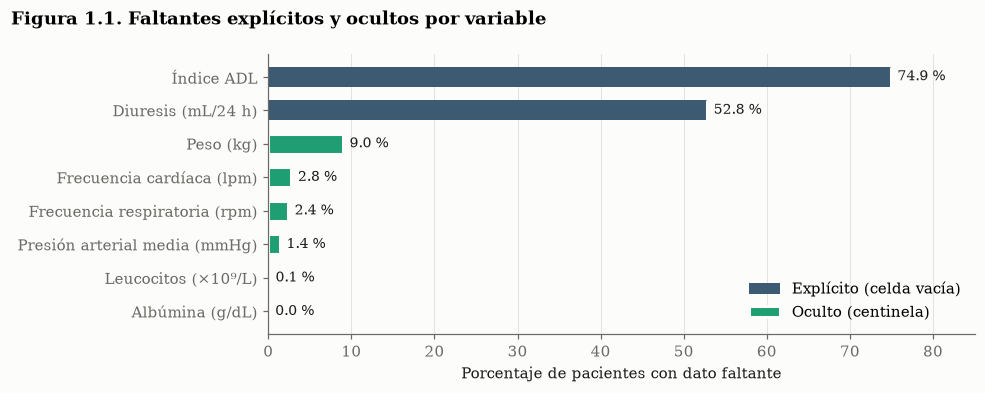

,explícito_%,total_%,oculto_%
adld3p,74.910,74.910,0.000
urin1,52.800,52.800,0.000
wtkilo1,0.000,8.980,8.980
hrt1,0.000,2.770,2.770
resp1,0.000,2.370,2.370
meanbp1,0.000,1.390,1.390
wblc1,0.000,0.070,0.070
alb1,0.000,0.030,0.030


In [5]:
miss = missingness_table(df_raw.drop(columns=["los", "log_los"]), df.drop(columns=["los", "log_los"]))
miss = miss.drop(index=["dthdte", "dschdte"], errors="ignore")  # fechas post-tratamiento

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(miss))[::-1]
ax.barh(y, miss["explícito_%"], color="#3d5a73", height=0.6, label="Explícito (celda vacía)")
ax.barh(y, miss["oculto_%"], left=miss["explícito_%"], color=viz.THIRD, height=0.6,
        label="Oculto (centinela)", edgecolor=viz.SURFACE, linewidth=2)
for yi, tot in zip(y, miss["total_%"]):
    ax.text(tot + 0.8, yi, f"{tot:.1f} %", va="center", fontsize=9, color=viz.INK)
ax.set_yticks(y, [cfg.LABELS.get(c, c) if c not in ("adld3p", "urin1") else
                  {"adld3p": "Índice ADL", "urin1": "Diuresis (mL/24 h)"}[c] for c in miss.index])
ax.set_xlabel("Porcentaje de pacientes con dato faltante")
ax.set_xlim(0, 85)
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
viz.figure_title(fig, "1.1", "Faltantes explícitos y ocultos por variable")
fig.tight_layout()
save(fig, "fig_1_1_faltantes")
plt.show()
miss.round(2)

## 1.2 Mecanismo de pérdida de datos: MCAR, MAR o MNAR

Sea $R_j$ el indicador de que la variable $X_j$ falta ($R_j = 1$). La clasificación de Rubin (1976) distingue:

- **MCAR** (*missing completely at random*): $P(R_j \mid X_{obs}, X_{mis}) = P(R_j)$. La pérdida no depende de nada.
- **MAR** (*missing at random*): $P(R_j \mid X_{obs}, X_{mis}) = P(R_j \mid X_{obs})$. Depende solo de variables observadas.
- **MNAR** (*missing not at random*): $P(R_j \mid X_{obs}, X_{mis})$ depende del propio valor no observado.

**Procedimiento.** Para cada variable se ajusta un modelo logit $R_j \sim Z + T$, con $Z$ = edad, APACHE, probabilidad de sobrevida, presión media, PaO₂/FiO₂, creatinina, orden de no reanimar, escala de coma e índice DASI. El test de razón de verosimilitud contrasta $H_0$: todos los coeficientes son nulos, que es la implicancia observable de MCAR; el estadístico sigue una $\chi^2$ con tantos grados de libertad como predictores. Rechazar $H_0$ descarta MCAR.

MNAR no puede demostrarse, porque el valor faltante es inobservable por definición. Como indicio se agrega el resultado $Y$ al logit: si $R_j$ se asocia con la mortalidad **aun condicionando en $Z$ y $T$**, la pérdida depende de información que $Z$ no captura.

In [6]:
Z_MISS = ["age", "aps1", "surv2md1", "meanbp1", "pafi1", "crea1", "dnr1", "scoma1", "das2d3pc"]
mech = pd.DataFrame([
    missingness_mechanism(df, col, [z for z in Z_MISS if z != col], cfg.TREATMENT, cfg.OUTCOME_BIN)
    for col in ["adld3p", "urin1", "wtkilo1", "hrt1", "resp1", "meanbp1"]
]).set_index("variable")
mech_show = mech.copy()
mech_show["p_MCAR"] = mech_show["p_MCAR"].map(inf.fmt_p)
mech_show["p_resultado | Z,T"] = mech_show["p_resultado | Z,T"].map(inf.fmt_p)
mech_show.round(2)

,faltante_%,"LR_chi2 (R~Z,T)",gl,p_MCAR,OR_tratamiento,"OR_resultado | Z,T","p_resultado | Z,T"
variable,,,,,,,
adld3p,74.910,"1,150.850",10,< 10⁻¹⁶,1.850,4.930,< 10⁻¹⁶
urin1,52.800,32.690,10,3.07 × 10⁻⁴,0.770,1.080,0.2430
wtkilo1,8.980,223.470,10,< 10⁻¹⁶,0.880,0.910,0.4208
hrt1,2.770,452.090,10,< 10⁻¹⁶,1.000,0.710,0.0726
resp1,2.370,366.520,10,< 10⁻¹⁶,0.680,0.600,0.0156
meanbp1,1.390,405.620,9,< 10⁻¹⁶,1.450,0.290,3.09 × 10⁻⁵


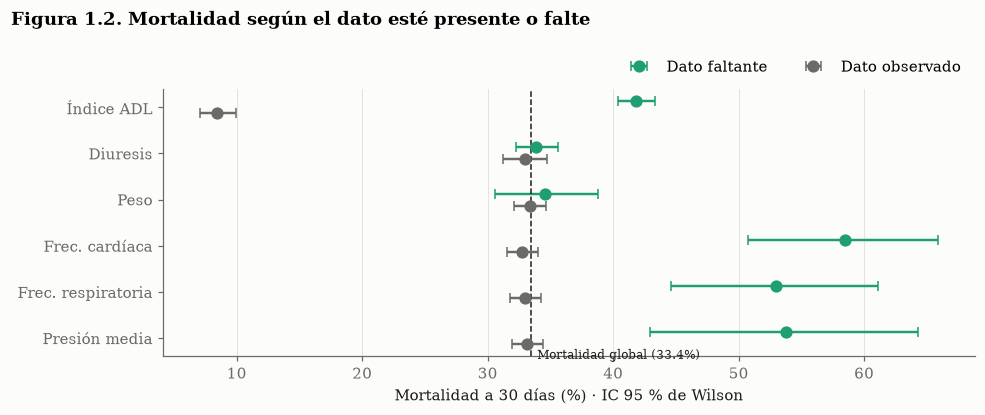

In [7]:
names = {"adld3p": "Índice ADL", "urin1": "Diuresis", "wtkilo1": "Peso",
         "hrt1": "Frec. cardíaca", "resp1": "Frec. respiratoria", "meanbp1": "Presión media"}
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, col in enumerate(list(names)[::-1]):
    for state, color, dy in [(True, viz.THIRD, 0.13), (False, viz.MUTED, -0.13)]:
        sub = df.loc[df[col].isna() == state, cfg.OUTCOME_BIN]
        lo, hi = inf.wilson_ci(sub.sum(), len(sub))
        ax.errorbar(sub.mean() * 100, i + dy, xerr=[[100 * (sub.mean() - lo)], [100 * (hi - sub.mean())]],
                    fmt="o", ms=7, color=color, capsize=3, lw=1.6,
                    label=("Dato faltante" if state else "Dato observado") if i == 0 else None)
ax.axvline(df[cfg.OUTCOME_BIN].mean() * 100, color=viz.INK, lw=1, ls="--")
ax.text(df[cfg.OUTCOME_BIN].mean() * 100 + 0.5, -0.45, f"Mortalidad global ({df[cfg.OUTCOME_BIN].mean():.1%})", fontsize=8, color=viz.INK)
ax.set_yticks(range(len(names)), list(names.values())[::-1])
ax.set_xlabel("Mortalidad a 30 días (%) · IC 95 % de Wilson")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
ax.grid(axis="y", visible=False)
viz.figure_title(fig, "1.2", "Mortalidad según el dato esté presente o falte")
fig.tight_layout()
save(fig, "fig_1_2_mortalidad_faltantes")
plt.show()

**Interpretación y estrategia de imputación.** Se rechaza MCAR para las seis variables ($p < 0{,}001$ en todos los casos), de modo que **ninguna pérdida es completamente aleatoria** y eliminar filas incompletas (*listwise deletion*) sesgaría la muestra.

| Variable | Faltante | Diagnóstico | Evidencia | Estrategia |
|---|---|---|---|---|
| Índice ADL (`adld3p`) | 74,9 % | **MNAR probable** | Quienes no tienen el dato tienen 4,9 veces más chances de morir a 30 días aun ajustando por gravedad ($p < 10^{-49}$). El índice se relevaba con el paciente en los primeros días: falta justamente cuando el paciente no podía responder. | **Se excluye.** Imputarlo supondría MAR, y esa hipótesis es insostenible aquí. |
| Diuresis (`urin1`) | 52,8 % | **MAR** | La pérdida depende de $Z$ y de $T$ ($p = 0{,}0003$), pero no de $Y$ condicional en $Z$ ($p = 0{,}24$). | **Se excluye:** con más de la mitad imputada, la variable aportaría más ruido que información. |
| Peso (`wtkilo1`) | 9,0 % (oculto) | **MAR** | Depende de $Z$ ($p < 10^{-41}$) y no de $Y$ condicional en $Z$ ($p = 0{,}42$). | Mediana estimada solo en *train* + indicador de faltante. |
| Frecuencia cardíaca (`hrt1`) | 2,8 % (oculto) | **MAR** | Depende de $Z$ ($p < 10^{-90}$); asociación con $Y$ no significativa al 5 % ($p = 0{,}07$). | Mediana en *train* + indicador. |
| Frecuencia respiratoria y presión media (`resp1`, `meanbp1`) | 2,4 % y 1,4 % (oculto) | **MNAR posible** | Asociación con $Y$ aun condicionando en $Z$ ($p = 0{,}016$ y $p < 10^{-4}$). Sin ajustar, los pacientes con cero mueren más (53 %, Figura 1.2), pero su APACHE III medio es de 78 a 87 puntos frente a 54 del resto. Al condicionar en APACHE, la asociación se invierte (OR < 1): el cero ya está contabilizado dentro del score como un valor extremo, lo que sugiere que podría ser una **medición real** (paciente en paro cardiorrespiratorio) y no un faltante. | Mediana en *train* + **indicador**: el indicador preserva la información de que se registró un cero, sea faltante o paro. Se revisan en el análisis de sensibilidad de la Fase 4. |
| Diagnóstico secundario (`cat2`) | 79,1 % | **Estructural** | La ausencia significa "sin diagnóstico secundario". | Categoría propia. |

El **indicador de faltante** permite que los modelos aprovechen el carácter informativo de la pérdida (Figura 1.2) sin inventar el valor. La imputación por mediana se elige frente a la imputación iterativa porque afecta a menos del 10 % de cada variable, es transparente y se ajusta **exclusivamente sobre el conjunto de entrenamiento** dentro de los pipelines de las Fases 2 y 3, lo que evita la fuga de información del conjunto de prueba.

## 1.3 Análisis univariado: distribuciones y colas pesadas

La Figura 1.3 compara la distribución de las principales variables continuas entre pacientes con y sin RHC mediante estimaciones de densidad por núcleo (KDE).

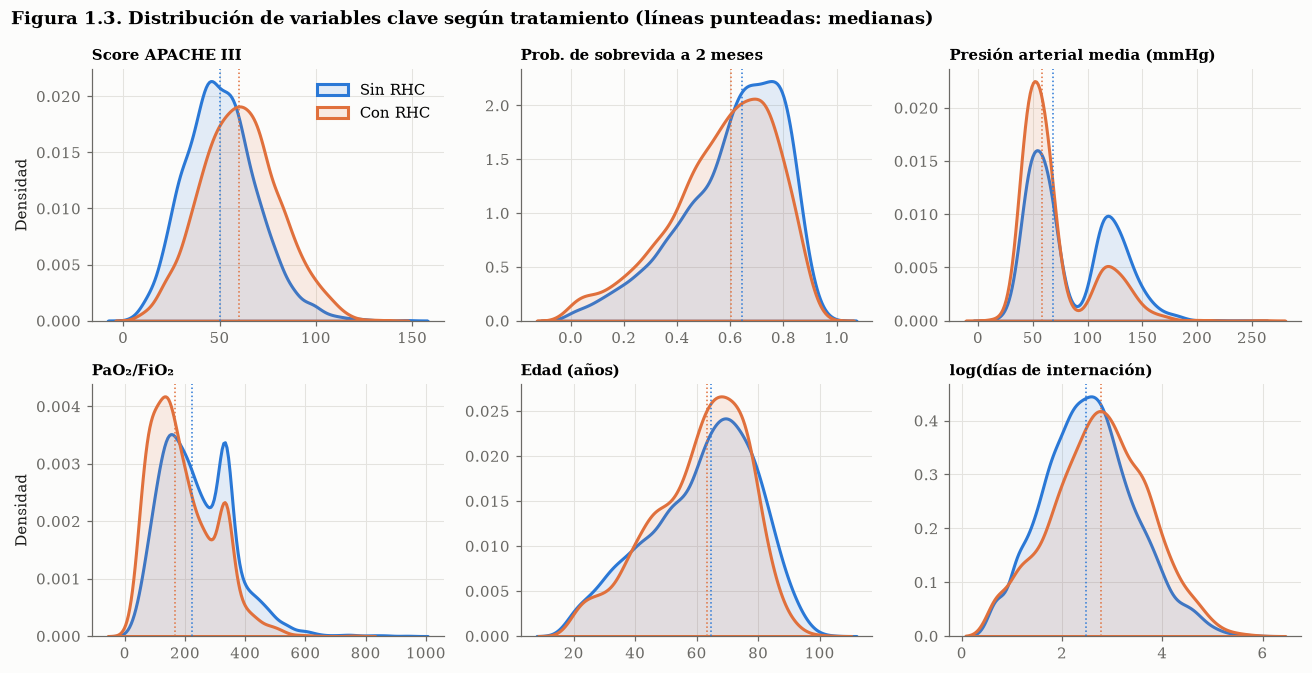

In [8]:
vars_kde = ["aps1", "surv2md1", "meanbp1", "pafi1", "age", "log_los"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, v in zip(axes.flat, vars_kde):
    for t, lab in [(0, "Sin RHC"), (1, "Con RHC")]:
        x = df.loc[df[cfg.TREATMENT] == t, v].dropna()
        sns.kdeplot(x, ax=ax, color=viz.GROUP_COLORS[t], lw=2, fill=True, alpha=0.12, label=lab)
        ax.axvline(x.median(), color=viz.GROUP_COLORS[t], lw=1, ls=":")
    ax.set_title({"surv2md1": "Prob. de sobrevida a 2 meses"}.get(v, cfg.LABELS[v]), fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Densidad" if ax in axes[:, 0] else "")
axes[0, 0].legend(loc="upper right")
viz.figure_title(fig, "1.3", "Distribución de variables clave según tratamiento (líneas punteadas: medianas)")
fig.tight_layout()
save(fig, "fig_1_3_kde_tratamiento")
plt.show()

In [9]:
num_cols = cfg.NUMERIC_FEATURES + ["los"]
shape = pd.DataFrame({
    "n": df[num_cols].count(),
    "media": df[num_cols].mean(),
    "mediana": df[num_cols].median(),
    "asimetría": df[num_cols].apply(lambda s: stats.skew(s.dropna())),
    "curtosis_exceso": df[num_cols].apply(lambda s: stats.kurtosis(s.dropna())),
}).sort_values("curtosis_exceso", ascending=False)
shape.round(2)

,n,media,mediana,asimetría,curtosis_exceso
bili1,5735,2.270,1.010,5.600,38.150
wblc1,5731,15.660,14.100,3.550,29.840
los,5734,21.490,14.000,3.910,25.270
crea1,5735,2.130,1.500,3.200,14.880
paco21,5735,38.750,37.000,2.170,9.180
wtkilo1,5220,74.520,72.200,1.210,3.830
ph1,5735,7.390,7.400,-1.220,3.480
pot1,5735,4.070,3.800,1.270,2.510
edu,5735,11.680,12.000,-0.090,1.960
sod1,5735,136.770,136.000,0.350,1.830


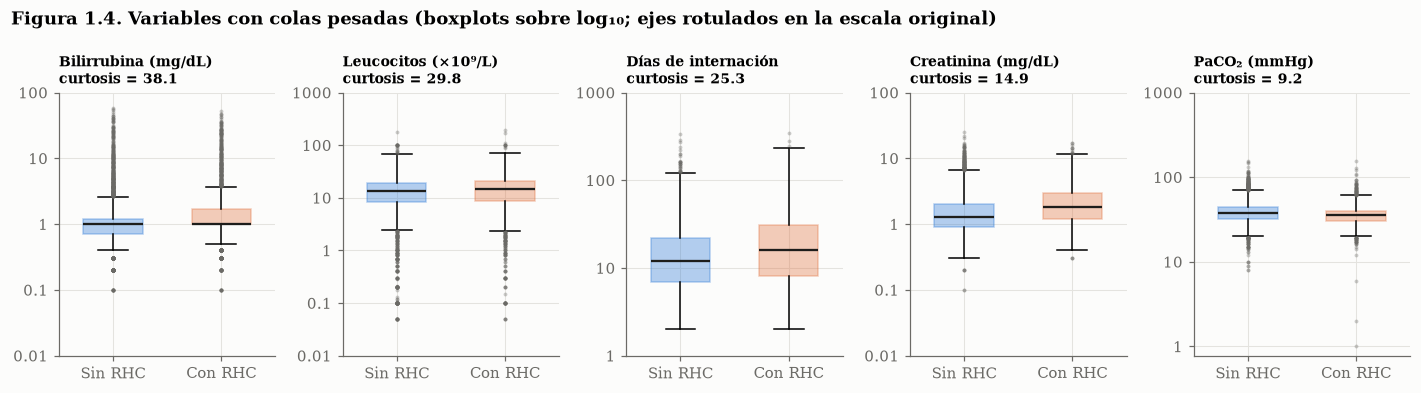

In [10]:
heavy = ["bili1", "wblc1", "los", "crea1", "paco21"]
fig, axes = plt.subplots(1, len(heavy), figsize=(13, 3.6))
for ax, v in zip(axes, heavy):
    data = [np.log10(df.loc[df[cfg.TREATMENT] == t, v].dropna()) for t in (0, 1)]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=True,
                    flierprops=dict(marker="o", ms=2.5, alpha=0.35, mec="none", mfc=viz.MUTED),
                    medianprops=dict(color=viz.INK, lw=1.5))
    for patch, t in zip(bp["boxes"], (0, 1)):
        patch.set(facecolor=viz.GROUP_COLORS[t], alpha=0.35, edgecolor=viz.GROUP_COLORS[t])
    ticks = np.arange(np.floor(min(d.min() for d in data)), np.ceil(max(d.max() for d in data)) + 1)
    ax.set_yticks(ticks, [f"{10 ** k:g}" for k in ticks])
    ax.set_xticks([1, 2], ["Sin RHC", "Con RHC"])
    ax.set_title(f"{cfg.LABELS[v]}\ncurtosis = {stats.kurtosis(df[v].dropna()):.1f}", fontsize=9)
viz.figure_title(fig, "1.4", "Variables con colas pesadas (boxplots sobre log₁₀; ejes rotulados en la escala original)")
fig.tight_layout()
save(fig, "fig_1_4_colas_pesadas")
plt.show()

**Interpretación.** La Figura 1.3 anticipa el problema central del trabajo: los pacientes con RHC llegan **más graves**. Su APACHE III está desplazado hacia la derecha, y su presión media y su índice PaO₂/FiO₂ (oxigenación), hacia la izquierda. Tratados y controles no son comparables al ingreso.

La tabla de forma y la Figura 1.4 documentan las **colas pesadas**: la bilirrubina (curtosis en exceso de 38), los leucocitos (30), los días de internación (25), la creatinina (15) y la PaCO₂ (9) se alejan marcadamente de la normal.

La auditoría también muestra cuánto puede fabricar un solo error. Sobre el dato crudo, la albúmina tenía una curtosis de 210; tras eliminar los dos valores imposibles (11 y 29 g/dL, probablemente 1,1 y 2,9 con la coma desplazada), la curtosis cae a 0,5. Esa "cola pesada" era un artefacto de tipeo, no una propiedad de la variable.

Dos consecuencias metodológicas se arrastran a las fases siguientes:

1. La duración de la internación se modela en **escala logarítmica**, que reduce la asimetría de 3,9 a 0,2 (Figura 1.3, panel inferior derecho).
2. Las asociaciones entre variables se miden también con **Spearman**, que es robusto a valores extremos (sección 1.4).

## 1.4 Análisis bivariado: Pearson frente a Spearman y confusión por diagnóstico

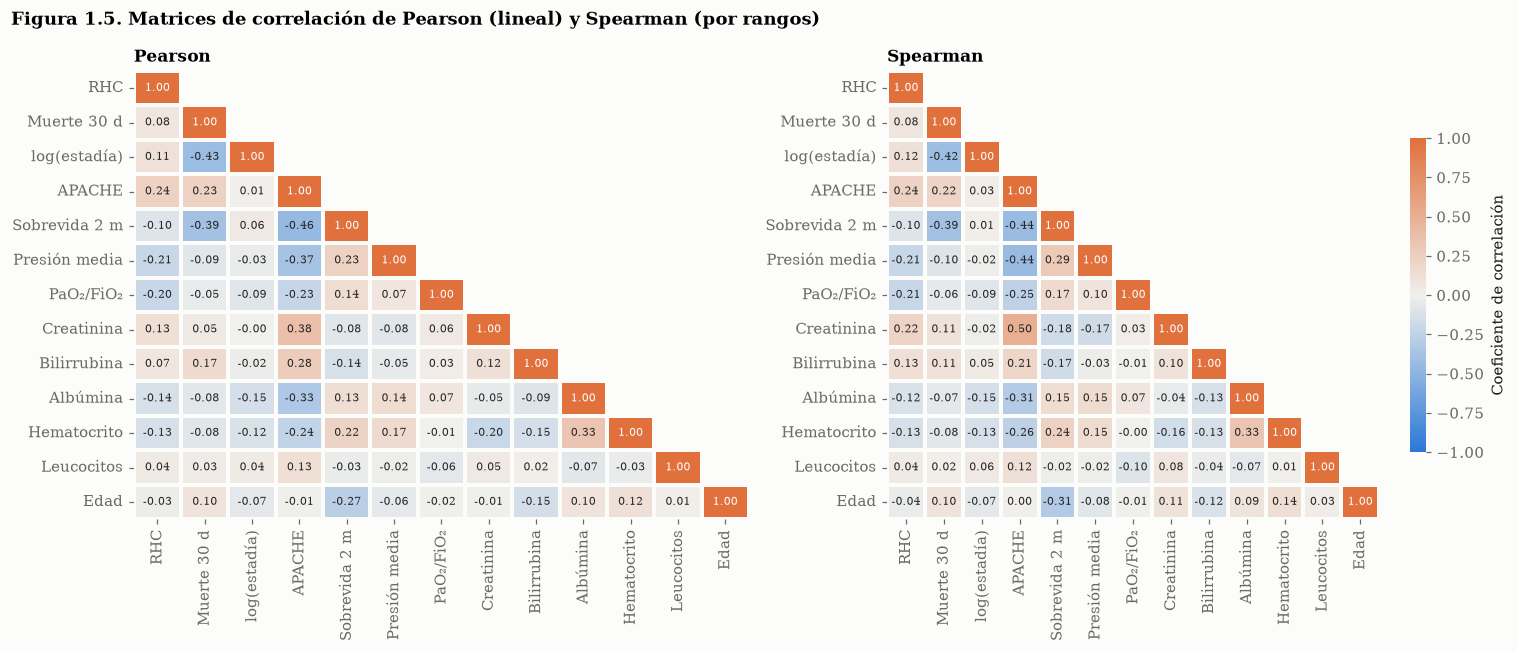

Mayores discrepancias |Spearman − Pearson|:
APACHE         Creatinina   0.122
Creatinina     Edad         0.117
Sobrevida 2 m  Creatinina   0.093
RHC            Creatinina   0.086
Presión media  Creatinina   0.082


In [11]:
corr_vars = ["rhc", "dth30", "log_los", "aps1", "surv2md1", "meanbp1", "pafi1",
             "crea1", "bili1", "alb1", "hema1", "wblc1", "age"]
short = {"rhc": "RHC", "dth30": "Muerte 30 d", "log_los": "log(estadía)", "aps1": "APACHE",
         "surv2md1": "Sobrevida 2 m", "meanbp1": "Presión media", "pafi1": "PaO₂/FiO₂",
         "crea1": "Creatinina", "bili1": "Bilirrubina", "alb1": "Albúmina",
         "hema1": "Hematocrito", "wblc1": "Leucocitos", "age": "Edad"}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    c = df[corr_vars].corr(method=method).rename(index=short, columns=short)
    mask = np.triu(np.ones_like(c, dtype=bool), k=1)
    sns.heatmap(c, mask=mask, cmap=viz.DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
                annot_kws={"size": 7}, linewidths=1.5, linecolor=viz.SURFACE, cbar=method == "spearman",
                cbar_kws={"shrink": 0.7, "label": "Coeficiente de correlación"}, ax=ax)
    ax.set_title(method.capitalize(), fontsize=11)
    ax.grid(False)
viz.figure_title(fig, "1.5", "Matrices de correlación de Pearson (lineal) y Spearman (por rangos)")
fig.tight_layout()
save(fig, "fig_1_5_correlaciones")
plt.show()

gap = (df[corr_vars].corr("spearman") - df[corr_vars].corr("pearson")).abs()
gap = gap.where(np.triu(np.ones_like(gap, dtype=bool), k=1)).stack().sort_values(ascending=False)
print("Mayores discrepancias |Spearman − Pearson|:")
print(gap.head(5).rename(index=short).round(3).to_string())

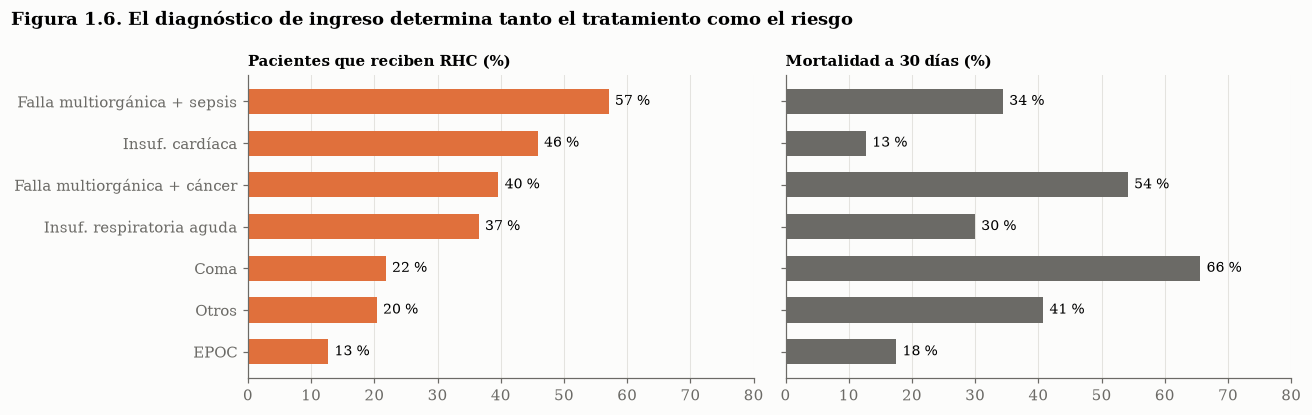

,n,tasa_RHC,mortalidad_30d,APACHE_medio
dx,,,,
EPOC,457,0.127,0.175,48.118
Otros,270,0.204,0.407,50.778
Coma,436,0.218,0.656,45.821
Insuf. respiratoria aguda,2490,0.365,0.300,53.847
Falla multiorgánica + cáncer,399,0.396,0.541,67.769
Insuf. cardíaca,456,0.458,0.127,39.443
Falla multiorgánica + sepsis,1227,0.570,0.344,64.169


In [12]:
dx_map = {"ARF": "Insuf. respiratoria aguda", "MOSF w/Sepsis": "Falla multiorgánica + sepsis",
          "MOSF w/Malignancy": "Falla multiorgánica + cáncer", "CHF": "Insuf. cardíaca",
          "COPD": "EPOC", "Coma": "Coma", "Cirrhosis": "Otros", "Lung Cancer": "Otros",
          "Colon Cancer": "Otros"}
df["dx"] = df["cat1"].astype(str).map(dx_map).astype("category")
by_dx = df.groupby("dx", observed=True).agg(
    n=("rhc", "size"), tasa_RHC=("rhc", "mean"), mortalidad_30d=("dth30", "mean"),
    APACHE_medio=("aps1", "mean")).sort_values("tasa_RHC")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
yy = np.arange(len(by_dx))
axes[0].barh(yy, by_dx["tasa_RHC"] * 100, color=viz.RHC, height=0.6)
axes[1].barh(yy, by_dx["mortalidad_30d"] * 100, color=viz.MUTED, height=0.6)
for ax, col in zip(axes, ["tasa_RHC", "mortalidad_30d"]):
    for yi, v in zip(yy, by_dx[col]):
        ax.text(v * 100 + 1, yi, f"{v * 100:.0f} %", va="center", fontsize=9)
    ax.set_xlim(0, 80)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(yy, by_dx.index)
axes[0].set_title("Pacientes que reciben RHC (%)", fontsize=10)
axes[1].set_title("Mortalidad a 30 días (%)", fontsize=10)
viz.figure_title(fig, "1.6", "El diagnóstico de ingreso determina tanto el tratamiento como el riesgo")
fig.tight_layout()
save(fig, "fig_1_6_diagnostico")
plt.show()
by_dx.round(3)

**Interpretación.**

- **Pearson frente a Spearman.** Las discrepancias se concentran en las variables de colas pesadas (creatinina, bilirrubina): unos pocos valores extremos alteran el coeficiente de Pearson, mientras que Spearman, al trabajar con rangos, refleja mejor la asociación monótona.
- **Confusión por indicación.** El RHC se asocia con mayor gravedad (Spearman de 0,24 con APACHE, −0,21 con presión media y con PaO₂/FiO₂), y la gravedad se asocia con la mortalidad. Además, la Figura 1.6 muestra que el diagnóstico de ingreso condiciona ambas cosas: los pacientes con falla multiorgánica y sepsis reciben RHC con frecuencia mucho mayor que los pacientes en coma o con EPOC. El caso de la insuficiencia cardíaca es revelador: recibe RHC en el 46 % de los casos y, sin embargo, tiene la mortalidad más baja (13 %). El diagnóstico influye en el tratamiento por razones clínicas propias, no solo por gravedad. Es, por lo tanto, un **confusor** que debe incluirse en el conjunto de ajuste de la Fase 4.
- **Estadía y mortalidad.** La correlación entre log(estadía) y muerte a 30 días es fuertemente negativa (−0,42): quien muere temprano tiene, por construcción, una internación corta. Este **truncamiento por muerte** impide interpretar la duración de la internación como un indicador de mala evolución y se retoma en la Fase 4 al discutir colisionadores.
- **Multicolinealidad estructural.** El APACHE III es un score construido a partir de las variables fisiológicas del día 1, y la probabilidad de sobrevida a 2 meses es una predicción del modelo SUPPORT que también las incorpora. La colinealidad es, entonces, **estructural por diseño**: se cuantifica con VIF en la Fase 2.

## 1.5 Contrastes de hipótesis

Se plantean tres contrastes con relevancia directa para la decisión clínica. Todos son bilaterales, con $\alpha = 0{,}05$ fijado a priori.

| | Hipótesis | Pregunta de negocio | Estadístico elegido y justificación |
|---|---|---|---|
| **H1** | $H_0: \mu_{APACHE}^{RHC} = \mu_{APACHE}^{sin\,RHC}$ vs. $H_1: \neq$ | ¿Los pacientes tratados llegan más graves? (evidencia de confusión) | **t de Welch.** Con $n > 2.000$ por grupo, el TCL garantiza la normalidad aproximada de la media muestral; Welch no asume varianzas iguales. |
| **H2** | $H_0: p_{muerte}^{RHC} = p_{muerte}^{sin\,RHC}$ vs. $H_1: \neq$ | ¿Difiere la mortalidad a 30 días entre grupos? (efecto **ingenuo**) | **z de dos proporciones**, equivalente al $\chi^2$ de una tabla 2×2. Se cumple $n\hat p \geq 5$ y $n(1 - \hat p) \geq 5$. |
| **H3** | $H_0$: las distribuciones de días de internación son iguales vs. $H_1$: una está desplazada | ¿Los tratados consumen más días de cama? | **U de Mann-Whitney.** La curtosis de 25 desaconseja comparar medias; el test por rangos es robusto a las colas. |

Para cada contraste se reporta el estadístico, los grados de libertad, el $p$-valor exacto, el intervalo de confianza del 95 % para la diferencia y la magnitud del efecto.

In [13]:
t1 = df[cfg.TREATMENT] == 1
tests = pd.DataFrame({
    "H1 · APACHE III": inf.welch_test(df.loc[t1, "aps1"].to_numpy(), df.loc[~t1, "aps1"].to_numpy()),
    "H2 · Mortalidad 30 d": inf.two_proportions(df.loc[t1, "dth30"].to_numpy(), df.loc[~t1, "dth30"].to_numpy()),
    "H3 · Días de internación": inf.mann_whitney(df.loc[t1, "los"].dropna().to_numpy(),
                                                 df.loc[~t1, "los"].dropna().to_numpy()),
}).T
tests["p_valor"] = tests["p_valor"].astype(float).map(inf.fmt_p)
tests["decisión"] = ["Se rechaza H₀"] * 3
tests

,estadístico,valor,gl,p_valor,diferencia,IC_inf,IC_sup,efecto,medida_efecto,decisión
H1 · APACHE III,t de Welch,18.277,"4,356.759",< 10⁻¹⁶,9.805,8.754,10.857,0.506,d de Cohen,Se rechaza H₀
H2 · Mortalidad 30 d,z de dos proporciones,5.740,NaN,9.46 × 10⁻⁹,0.074,0.048,0.099,0.155,h de Cohen,Se rechaza H₀
H3 · Días de internación,U de Mann-Whitney,"4,422,828.500",NaN,< 10⁻¹⁶,4.000,3.000,5.000,0.141,biserial por rangos,Se rechaza H₀


In [14]:
h_obs = tests.loc["H2 · Mortalidad 30 d", "efecto"]
n1, n0 = int(t1.sum()), int((~t1).sum())
print(f"Potencia (1 − β) para detectar el efecto observado h = {h_obs:.3f}: "
      f"{inf.power_two_proportions(h_obs, n1, n0):.4f}")
print(f"Efecto mínimo detectable con 80 % de potencia y α = 0,05: h = {inf.min_detectable_h(n1, n0):.3f}")

Potencia (1 − β) para detectar el efecto observado h = 0.155: 0.9999
Efecto mínimo detectable con 80 % de potencia y α = 0,05: h = 0.076


**Interpretación.**

- **H1 · Gravedad.** Los pacientes con RHC tienen un APACHE III **9,8 puntos mayor** (IC 95 %: 8,8 a 10,9; $t = 18{,}3$ con 4.357 g.l.; $p = 5{,}8 \times 10^{-72}$). Una $d$ de Cohen de 0,51 indica un efecto **mediano**: la diferencia no es solo estadísticamente significativa, sino clínicamente relevante. Es evidencia directa de **confusión por indicación**: los médicos cateterizan a los pacientes más comprometidos.
- **H2 · Mortalidad.** La mortalidad a 30 días es de 38,0 % con RHC y 30,6 % sin RHC: una diferencia de **7,4 puntos porcentuales** (IC 95 %: 4,8 a 9,9; $z = 5{,}74$; $p = 9{,}5 \times 10^{-9}$). Este es el **efecto ingenuo**, y **no puede interpretarse como causal**, porque H1 mostró que los grupos no son comparables al ingreso. La Fase 4 estima cuánto de esta diferencia sobrevive al ajuste por confusores.
- **H3 · Uso de recursos.** La mediana de días de internación es **4 días mayor** en los pacientes tratados (IC 95 % bootstrap: 3 a 5; $p = 2{,}5 \times 10^{-19}$). La correlación biserial por rangos de 0,14 indica un efecto pequeño pero relevante para la planificación de camas de terapia intensiva.
- **Potencia.** Con 2.184 tratados y 3.551 controles, el estudio detecta con 80 % de potencia cualquier efecto $h \geq 0{,}076$. El efecto observado ($h = 0{,}155$) duplica ese umbral, y la potencia resultante es prácticamente 1. **El riesgo en este dataset no es la falta de potencia, sino el sesgo**: con $n$ grande, hasta un efecto espurio producido por confusión resulta "significativo".

## 1.6 ANOVA de un factor: días de internación según diagnóstico de ingreso

**Diseño.** Se evalúa si el valor esperado de log(días de internación) varía entre los siete grupos diagnósticos de la Figura 1.6:

$$H_0: \mu_1 = \mu_2 = \cdots = \mu_7 \qquad \text{vs.} \qquad H_1: \exists\, i \neq j \;/\; \mu_i \neq \mu_j$$

Las categorías cirrosis, cáncer de pulmón y cáncer de colon se agrupan en "Otros" porque el cáncer de colon tiene solo 7 pacientes y el de pulmón 39: grupos tan pequeños inflan la varianza del ANOVA y vuelven inestables las comparaciones *post-hoc*.

### El desafío metodológico: Shapiro-Wilk con muestras grandes

Con $n = 2.490$ en el grupo más numeroso, el test de Shapiro-Wilk tiene potencia para rechazar $H_0$ ante desviaciones microscópicas y sin consecuencias prácticas. Por eso el supuesto de normalidad se evalúa con **asimetría, curtosis y gráficos Q-Q**, y Shapiro-Wilk se reporta solo como referencia.

In [15]:
anova_df = df.dropna(subset=["los"])
norm = pd.concat({
    "Días (escala original)": inf.normality_profile({k: g["los"].to_numpy() for k, g in anova_df.groupby("dx", observed=True)}),
    "log(días)": inf.normality_profile({k: g["log_los"].to_numpy() for k, g in anova_df.groupby("dx", observed=True)}),
})
norm["p_SW"] = norm["p_SW"].map(inf.fmt_p)
norm.round(3)

grupo     n  asimetría  \
Días (escala original) 0                          Coma   436      3.466   
                       1                          EPOC   457      5.293   
                       2  Falla multiorgánica + cáncer   399      2.146   
                       3  Falla multiorgánica + sepsis  1226      3.756   
                       4               Insuf. cardíaca   456      3.836   
                       5     Insuf. respiratoria aguda  2490      3.265   
                       6                         Otros   270      3.777   
log(días)              0                          Coma   436      0.315   
                       1                          EPOC   457      0.513   
                       2  Falla multiorgánica + cáncer   399     -0.015   
                       3  Falla multiorgánica + sepsis  1226      0.008   
                       4               Insuf. cardíaca   456      0.453   
                       5     Insuf. respiratoria aguda  2490      0.136   
                       6                         Otros   270      0.108   

                          curtosis_exceso  Shapiro-Wilk W         p_SW  
Días (escala original) 0           18.569           0.658      < 10⁻¹⁶  
                       1           44.115           0.540      < 10⁻¹⁶  
                       2            6.693           0.794      < 10⁻¹⁶  
                       3           22.400           0.658      < 10⁻¹⁶  
                       4           19.771           0.607      < 10⁻¹⁶  
                       5           15.538           0.675      < 10⁻¹⁶  
                       6           22.691           0.675      < 10⁻¹⁶  
log(días)              0           -0.757           0.965  9.54 × 10⁻⁹  
                       1            0.587           0.980  5.66 × 10⁻⁶  
                       2           -0.653           0.986  8.48 × 10⁻⁴  
                       3           -0.298           0.994  1.44 × 10⁻⁴  
                       4            0.169           0.979  4.58 × 10⁻⁶  
                       5           -0.091           0.994  3.71 × 10⁻⁸  
                       6           -0.162           0.989       0.0475

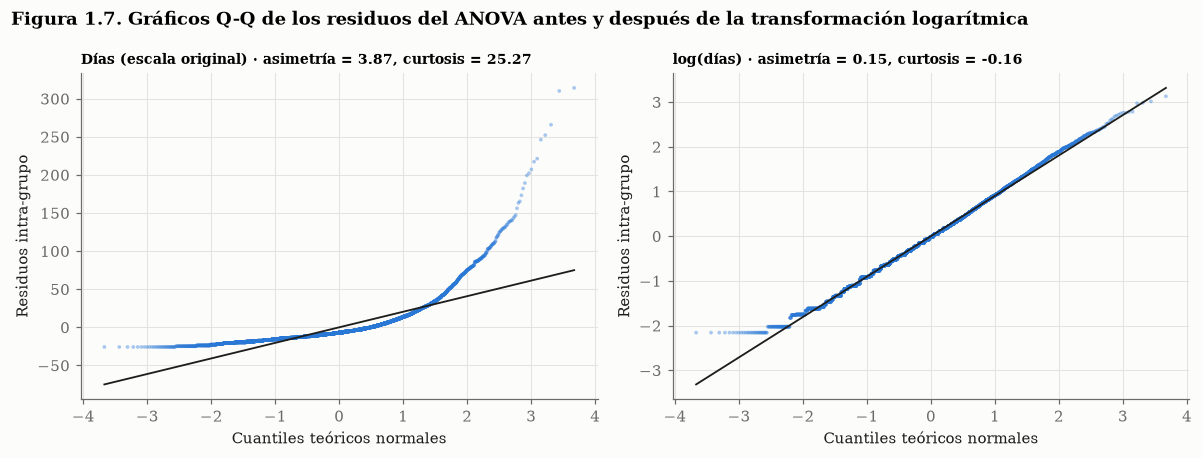

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, v, title in [(axes[0], "los", "Días (escala original)"), (axes[1], "log_los", "log(días)")]:
    resid = anova_df[v] - anova_df.groupby("dx", observed=True)[v].transform("mean")
    (osm, osr), (slope, intercept, _) = stats.probplot(resid, dist="norm")
    ax.scatter(osm, osr, s=6, alpha=0.4, color=viz.NO_RHC, edgecolor="none")
    ax.plot(osm, slope * osm + intercept, color=viz.INK, lw=1.2)
    ax.set_title(f"{title} · asimetría = {stats.skew(resid):.2f}, curtosis = {stats.kurtosis(resid):.2f}", fontsize=9)
    ax.set_xlabel("Cuantiles teóricos normales")
    ax.set_ylabel("Residuos intra-grupo")
viz.figure_title(fig, "1.7", "Gráficos Q-Q de los residuos del ANOVA antes y después de la transformación logarítmica")
fig.tight_layout()
save(fig, "fig_1_7_qq_anova")
plt.show()

**Lectura de la normalidad.** En escala original, los residuos tienen una cola derecha muy pesada (Figura 1.7, izquierda) y Shapiro-Wilk rechaza con $W$ entre 0,54 y 0,79. Tras la transformación logarítmica, la asimetría por grupo queda entre 0,0 y 0,5, la curtosis en exceso cerca de cero, y los puntos del Q-Q se alinean con la recta salvo en los extremos. Shapiro-Wilk **sigue rechazando** ($W \geq 0{,}96$), lo que ilustra la advertencia anterior: la desviación residual es irrelevante para el TCL con grupos de 270 a 2.490 observaciones. Se adopta **log(días)** como variable de respuesta.

In [17]:
res = inf.anova_battery(anova_df, "log_los", "dx")
anova_tab = pd.DataFrame({
    "Estadístico": [res["F_clásico"], res["Levene_W"], res["F_Welch"], res["H_Kruskal"]],
    "g.l.": [f"({res['gl'][0]}, {res['gl'][1]})", f"({res['gl'][0]}, {res['gl'][1]})",
             f"({res['gl_Welch'][0]:.0f}, {res['gl_Welch'][1]:.1f})", f"{res['gl'][0]}"],
    "p-valor": [inf.fmt_p(res[k]) for k in ["p_F", "p_Levene", "p_Welch", "p_Kruskal"]],
}, index=["ANOVA clásico (F)", "Levene / Brown-Forsythe (W)", "ANOVA de Welch (F)", "Kruskal-Wallis (H)"])
display(anova_tab.round(2))
print(f"Tamaño del efecto: η² = {res['eta2']:.3f} · ω² = {res['omega2']:.3f} · ε² (Kruskal-Wallis) = {res['epsilon2_KW']:.3f}")

,Estadístico,g.l.,p-valor
ANOVA clásico (F),49.990,"(6, 5727)",< 10⁻¹⁶
Levene / Brown-Forsythe (W),14.170,"(6, 5727)",4.35 × 10⁻¹⁶
ANOVA de Welch (F),49.870,"(6, 1358.1)",< 10⁻¹⁶
Kruskal-Wallis (H),284.460,6,< 10⁻¹⁶


Tamaño del efecto: η² = 0.050 · ω² = 0.049 · ε² (Kruskal-Wallis) = 0.050


**Interpretación.** El test de Levene en su versión de Brown-Forsythe (centrado en la mediana, robusta a colas) **rechaza la homogeneidad de varianzas**: el desvío de log(días) va de 0,81 (EPOC) a 1,02 (coma). Con varianzas y tamaños de grupo desiguales, el $F$ clásico puede distorsionar el error de tipo I, de modo que la decisión se apoya en dos alternativas robustas:

- el **ANOVA de Welch**, que pondera cada grupo por la inversa de su varianza y corrige los grados de libertad del denominador;
- el test de **Kruskal-Wallis**, no paramétrico, que compara rangos.

Ambos rechazan $H_0$ con $p$-valores prácticamente nulos: **la duración esperada de la internación difiere según el diagnóstico de ingreso.** El tamaño del efecto es pequeño ($\omega^2 \approx 0{,}05$): el diagnóstico explica alrededor del 5 % de la variabilidad de log(días). Es una señal clara pero insuficiente por sí sola para predecir la estadía, lo que justifica el modelo multivariado de la Fase 2.

In [18]:
ph = inf.posthoc(anova_df, "log_los", "dx")
ph_show = ph.copy()
for c in ["p_Tukey", "p_Bonferroni"]:
    ph_show[c] = ph_show[c].astype(float).map(inf.fmt_p)
print(f"Pares significativos: Tukey = {ph['rechaza_Tukey'].sum()} · Bonferroni = {ph['rechaza_Bonferroni'].sum()} "
      f"de {len(ph)} · Coincidencia de decisiones: {(ph['rechaza_Tukey'] == ph['rechaza_Bonferroni']).mean():.0%}")
ph_show.round(3)

Pares significativos: Tukey = 14 · Bonferroni = 14 de 21 · Coincidencia de decisiones: 100%


,group1,group2,dif_medias,p_Tukey,p_Bonferroni,rechaza_Tukey,rechaza_Bonferroni
0,Coma,EPOC,0.242,0.0013,0.0022,True,True
1,Coma,Falla multiorgánica + cáncer,0.180,0.0625,0.1391,False,False
2,Coma,Falla multiorgánica + sepsis,0.573,< 10⁻¹⁶,< 10⁻¹⁶,True,True
3,Coma,Insuf. cardíaca,-0.054,0.9727,1.0000,False,False
4,Coma,Insuf. respiratoria aguda,0.441,< 10⁻¹⁶,5.30 × 10⁻¹⁵,True,True
5,Coma,Otros,0.081,0.9085,1.0000,False,False
6,EPOC,Falla multiorgánica + cáncer,-0.062,0.9547,1.0000,False,False
7,EPOC,Falla multiorgánica + sepsis,0.331,< 10⁻¹⁶,8.34 × 10⁻¹¹,True,True
8,EPOC,Insuf. cardíaca,-0.296,< 10⁻¹⁶,1.17 × 10⁻⁶,True,True
9,EPOC,Insuf. respiratoria aguda,0.199,3.00 × 10⁻⁴,5.09 × 10⁻⁵,True,True


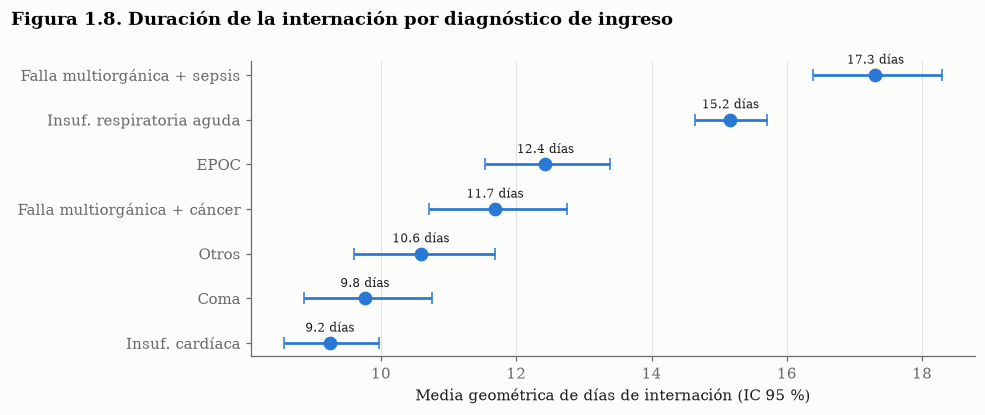

In [19]:
summ = anova_df.groupby("dx", observed=True)["log_los"].agg(["mean", "std", "count"]).sort_values("mean")
summ["ic"] = stats.t.ppf(0.975, summ["count"] - 1) * summ["std"] / np.sqrt(summ["count"])
fig, ax = plt.subplots(figsize=(9, 3.8))
yy = np.arange(len(summ))
ax.errorbar(np.exp(summ["mean"]), yy,
            xerr=[np.exp(summ["mean"]) - np.exp(summ["mean"] - summ["ic"]),
                  np.exp(summ["mean"] + summ["ic"]) - np.exp(summ["mean"])],
            fmt="o", ms=8, color=viz.NO_RHC, ecolor=viz.NO_RHC, capsize=4, lw=1.8)
for yi, m in zip(yy, np.exp(summ["mean"])):
    ax.text(m, yi + 0.25, f"{m:.1f} días", ha="center", fontsize=8, color=viz.INK)
ax.set_yticks(yy, summ.index)
ax.set_xlabel("Media geométrica de días de internación (IC 95 %)")
ax.grid(axis="y", visible=False)
viz.figure_title(fig, "1.8", "Duración de la internación por diagnóstico de ingreso")
fig.tight_layout()
save(fig, "fig_1_8_anova_medias")
plt.show()

**Comparaciones múltiples.** Con 7 grupos hay 21 comparaciones de a pares. Sin corrección, la probabilidad de cometer al menos un error de tipo I sería $1 - 0{,}95^{21} \approx 66\%$. Se contrastan dos formas de controlar la tasa de error por familia:

- **Tukey HSD**: usa la distribución del rango studentizado y supone varianzas iguales.
- **Bonferroni sobre tests t de Welch**: más conservador ($\alpha / 21$ por comparación), pero válido con varianzas desiguales.

**Ambos métodos coinciden en las 21 decisiones** (14 pares con diferencias significativas), por lo que las conclusiones no dependen del supuesto de homocedasticidad que Levene rechazó. La falla multiorgánica con sepsis es el diagnóstico con internaciones más largas (media geométrica de 17,3 días), seguida por la insuficiencia respiratoria aguda (15,2 días). La insuficiencia cardíaca y el coma, en cambio, tienen las estadías más cortas (alrededor de 9,5 días) y no difieren significativamente entre sí. En el caso del coma, la estadía corta se explica en parte por el truncamiento por muerte identificado en la sección 1.4.

## 1.7 Síntesis de la Fase 1

| Hallazgo | Consecuencia para las fases siguientes |
|---|---|
| 896 valores centinela ocultos; el peso tenía 9 % de ceros imposibles | Se recodifican como faltantes; imputación por mediana **solo en train** + indicador |
| Ninguna pérdida es MCAR; el índice ADL es probablemente MNAR | `adld3p` y `urin1` se excluyen; los indicadores de faltante se conservan como predictores |
| Colas pesadas (curtosis en exceso de hasta 38) | Respuesta continua en escala logarítmica; se privilegian métodos robustos |
| Los tratados son más graves ($d = 0{,}51$ en APACHE) | La diferencia ingenua de mortalidad (+7,4 pp) está confundida: requiere el ajuste causal de la Fase 4 |
| El diagnóstico condiciona tratamiento y resultado | Es un confusor obligatorio en el DAG |
| La estadía está truncada por la muerte | No se usa como mediador ni como control en la Fase 4 |
| Colinealidad estructural entre APACHE y la fisiología | Se diagnostica con VIF en la Fase 2 |